# Flat-years attainability study --- "was there carry to earn in 2022 / 2023 / 2025?"

**Question.** The delta-neutral funding-carry book (long spot / short USDT-perp, Binance+Bybit breadth,
daily rebalance, v4 drawdown overlay, idle-cash credit) earns an excess-of-rf edge that is strongly
**front-loaded**. v8.0 excess return by year: **2021 +31.5%, 2022 -0.5%, 2023 +1.7%, 2024 +8.6%,
2025 -0.2%, 2026 +2.0%** (5 mo). Before committing capital the owner wants an *a-posteriori* answer for
the flat years: **(a) did harvestable carry exist at all, and (b) if yes, was it outside our strategy
family, or just outside our knob settings?**

**Ground rules (this is Phase 1 --- descriptive / attainability).**
- **Hindsight is explicitly allowed** and every oracle is titled `(hindsight)`. A clean *"it was
  impossible --- the book correctly earned ~rf when there was nothing to harvest"* is a fully acceptable
  and valuable verdict.
- **Everything is judged in EXCESS of rf.** rf = the lake series `fred/tb3ms` (3-month T-bill, monthly,
  decimal annual), forward-filled to a daily index and divided by 365. Window mean ~3.3%/yr: ~0 in 2021,
  5%+ in 2023-24. On a market-neutral book that is a large, *time-varying* hurdle.
- **Oracles see FUNDING only.** They get perfect foresight of realized funding, select on it, but still
  eat whatever basis P&L happens and pay the **real v3.1 cost table** on turnover. No adaptation
  backtests are run here (that is Phase 2, gated on this verdict).

**Method map.** A1 supply (raw opportunity set, no book) + the breadth-vs-hurdle test of the
"absolute-gates-in-a-5%-world" hypothesis. A2 funding-timer oracles (month/day, veto-restricted &
unrestricted). A3 in-family hindsight-best over the 630-config grid. A4 decomposition of the actual book.
A5 the negative-carry (short-spot) bound. A6 the verdict table + Phase-2 recommendation.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ['svg']
import sys, time
from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.funding_carry.lab as H
from src.strategies.funding_carry import engine
from src.common import config as cfg
from src.data import query
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,PURPLE,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','#7048a8','0.6'
FLAT = [2022, 2023, 2025]                      # the years under investigation
def shade_flat(ax):
    for y in FLAT:
        ax.axvspan(pd.Timestamp(f'{y}-01-01'), pd.Timestamp(f'{y}-12-31'), color=AMBER, alpha=0.08, zorder=0)

t0 = time.time()
COSTS = cfg.load_config('strategies/funding_carry/v3.1.yaml')['costs']
one_way, round_trip = engine.round_trip_cost(COSTS)
par = H.validate_engine()
maj, non = H.universe(); P = H.load_panels(maj + non)
didx, syms, E = P['didx'], P['symbols'], P['E']
F, R = P['F'], P['R']
rfm = query.get('rates','fred','tb3ms','rates')['value']            # monthly, DECIMAL annual rate
def rf_apr_daily(idx):
    key = idx.to_period('M').to_timestamp()
    return pd.Series(rfm.reindex(key).ffill().values, index=idx)
RF_APR = rf_apr_daily(didx)                    # annual decimal, per day
RF_D   = RF_APR / 365.0                         # daily fraction
HOLD_COST_APR = round_trip * 365 / 30.0        # round-trip cost amortized over a typical 30d hold
print('engine parity:', 'OK' if par['ok'] else 'MISMATCH')
print(f'universe {len(syms)} names ({len(maj)} majors + {len(non)} others), {len(didx)} days, load {time.time()-t0:.0f}s')
print(f'one_way {one_way:.4f}  round_trip {round_trip:.4f}  30d-amortized cost hurdle {HOLD_COST_APR*100:.2f}%/yr')
print(f'rf window mean {RF_APR.mean()*100:.2f}%/yr  (2021 {RF_APR[didx.year==2021].mean()*100:.2f}  2023 {RF_APR[didx.year==2023].mean()*100:.2f}  2024 {RF_APR[didx.year==2024].mean()*100:.2f})')

2026-07-06 12:24:37,374 INFO     funding_carry.engine | funding_carry v1: net@1x ann=9.41% sharpe=6.41 turnover=9.1x (C:\Users\SamuelAhou\Documents\operator\results\funding_carry\v1\20260706T102437Z)


engine parity: OK
universe 466 names (5 majors + 461 others), 1977 days, load 15s
one_way 0.0019  round_trip 0.0038  30d-amortized cost hurdle 4.62%/yr
rf window mean 3.26%/yr  (2021 0.04  2023 5.07  2024 4.97)


In [2]:
# excess-of-rf per-year helpers (ANNUALIZED = mean*365, to match the ladder's by_year convention)
YEARS = list(range(2021, 2027))
def ann_exc(net):
    net = net.dropna(); ex = net - RF_D.reindex(net.index)
    return ex.groupby(ex.index.year).apply(lambda g: g.mean()*365)
def ann_exc_sharpe(net):
    net = net.dropna(); ex = net - RF_D.reindex(net.index)
    return ex.groupby(ex.index.year).apply(lambda g: (g.mean()*365)/(g.std()*np.sqrt(365)) if g.std()>0 else np.nan)
def full_exc_sharpe(net):
    net = net.dropna(); ex = net - RF_D.reindex(net.index)
    return (ex.mean()*365)/(ex.std()*np.sqrt(365))
def yr_table(net, turn_ann=None):
    a, s = ann_exc(net), ann_exc_sharpe(net)
    t = pd.DataFrame({'excess ann %': (a*100).round(2), 'excess Sharpe': s.round(2)})
    t.loc['ALL'] = [round(net.dropna().sub(RF_D.reindex(net.dropna().index)).mean()*365*100,2), round(full_exc_sharpe(net),2)]
    if turn_ann is not None: t['turnover x/yr'] = round(turn_ann,1)
    return t
STORE = {}   # collect per-year annualized excess (%) for the A6 verdict table

## A1. Carry supply --- the raw opportunity set (no book)

Before any strategy: **how much funding was there to harvest, and how does it compare to the true
hurdle?** For each name, its trailing realized-funding APR is the rolling 30-day funding sum annualized
(`F.rolling(30).sum() * 365/30`), masked to eligible days. This is a descriptive picture of supply --- no
selection, no vetoes, no costs.

The **breadth-vs-hurdle** panel is the direct test of the *"absolute gates in a 5% world"* hypothesis.
Per day we count names whose trailing-30d funding APR clears three gates:
- **(i) absolute 8%** --- the fixed `theta_in` the strategy actually uses;
- **(ii) rf + cost** --- the *true* break-even to beat cash after round-trip cost amortized over a 30d
  hold (`rf_apr` + ~4.6%); a name below this earns *less than idle cash net of trading it*;
- **(iii) rf + 8%** --- an rf-indexed version of our 8% premium.

(Universe = the clean Binance lab universe. Bybit-only names would add breadth post-2021-07, but Binance
suffices for the supply question and keeps the picture single-venue.)

Cross-sectional trailing-30d funding APR --- median of the daily cross-section, by year:


      median %  p75 %  p90 %
2021     25.54  30.27  33.53
2022      2.34   6.04   7.97
2023      7.83   9.64  10.52
2024     10.88  11.36  12.25
2025      4.44   7.41   9.66
2026      0.00   6.03   9.81


C:\Users\SamuelAhou\Documents\operator\.venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


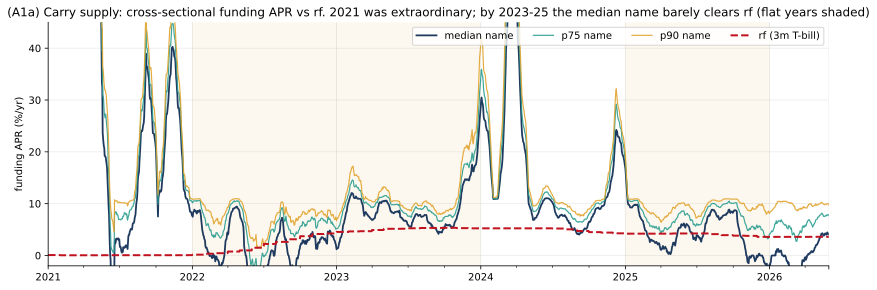

In [3]:
apr30 = (F.rolling(30).sum()*(365/30)).where(E)
med = apr30.median(axis=1); p75 = apr30.quantile(0.75, axis=1); p90 = apr30.quantile(0.90, axis=1)
sup_yr = pd.DataFrame({'median %': med, 'p75 %': p75, 'p90 %': p90}).groupby(didx.year).median()*100
print('Cross-sectional trailing-30d funding APR --- median of the daily cross-section, by year:')
print(sup_yr.round(2).to_string())
STORE['supply_median'] = (med.groupby(didx.year).median()*100).round(2)

fig, ax = plt.subplots(figsize=(14,4.4)); shade_flat(ax)
(med*100).plot(ax=ax, color=NAVY, lw=1.8, label='median name')
(p75*100).plot(ax=ax, color=TEAL, lw=1.2, alpha=0.9, label='p75 name')
(p90*100).plot(ax=ax, color=AMBER, lw=1.2, alpha=0.9, label='p90 name')
(RF_APR*100).plot(ax=ax, color=RED, lw=2.0, ls='--', label='rf (3m T-bill)')
ax.set_ylim(-2, 45); ax.set_ylabel('funding APR (%/yr)'); ax.legend(ncol=4, loc='upper right')
ax.set_title('(A1a) Carry supply: cross-sectional funding APR vs rf. 2021 was extraordinary; by 2023-25 the median name barely clears rf (flat years shaded)')
plt.show()

Breadth --- avg # names/day clearing each gate, by year:
      abs 8%  rf+cost (true break-even)  rf+8%
2021    80.6                       86.6   80.5
2022    23.0                       31.8   14.0
2023    92.4                       64.2   27.9
2024   173.1                      145.2   90.0
2025    99.3                       81.8    5.6
2026    68.6                       64.8    2.8


C:\Users\SamuelAhou\Documents\operator\.venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


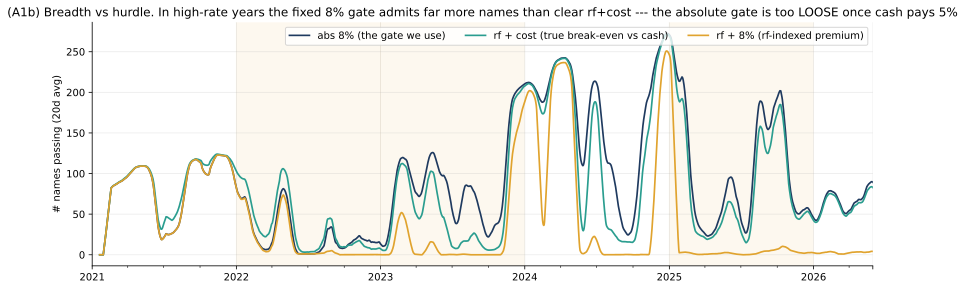

In [4]:
abs8  = (apr30 > 0.08).sum(axis=1)
rfcst = apr30.gt(RF_APR + HOLD_COST_APR, axis=0).sum(axis=1)
rf8   = apr30.gt(RF_APR + 0.08, axis=0).sum(axis=1)
brd_yr = pd.DataFrame({'abs 8%': abs8, 'rf+cost (true break-even)': rfcst, 'rf+8%': rf8}).groupby(didx.year).mean()
print('Breadth --- avg # names/day clearing each gate, by year:')
print(brd_yr.round(1).to_string())

fig, ax = plt.subplots(figsize=(14,4.4)); shade_flat(ax)
abs8.rolling(20).mean().plot(ax=ax, color=NAVY, lw=1.7, label='abs 8% (the gate we use)')
rfcst.rolling(20).mean().plot(ax=ax, color=TEAL, lw=1.7, label='rf + cost (true break-even vs cash)')
rf8.rolling(20).mean().plot(ax=ax, color=AMBER, lw=1.7, label='rf + 8% (rf-indexed premium)')
ax.set_ylabel('# names passing (20d avg)'); ax.legend(ncol=3, loc='upper right')
ax.set_title('(A1b) Breadth vs hurdle. In high-rate years the fixed 8% gate admits far more names than clear rf+cost --- the absolute gate is too LOOSE once cash pays 5%')
plt.show()

C:\Users\SamuelAhou\Documents\operator\.venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


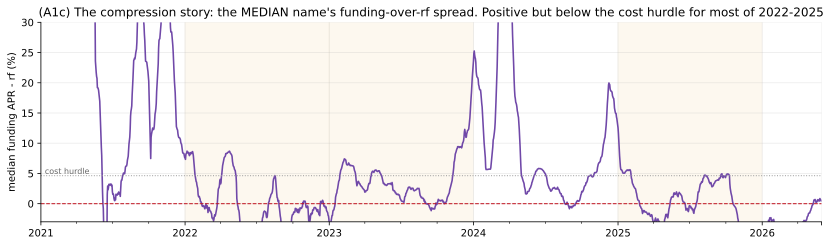

median-name funding-minus-rf spread, by year (%):
2021    25.49
2022    -0.78
2023     2.75
2024     5.66
2025     0.22
2026    -3.57


In [5]:
spread = (med - RF_APR)*100
fig, ax = plt.subplots(figsize=(14,3.6)); shade_flat(ax)
spread.plot(ax=ax, color=PURPLE, lw=1.6); ax.axhline(0, color=RED, lw=1, ls='--')
ax.axhline(HOLD_COST_APR*100, color=GREY, lw=1, ls=':'); ax.text(didx[10], HOLD_COST_APR*100+0.3, 'cost hurdle', color='0.4', fontsize=8)
ax.set_ylabel('median funding APR - rf (%)'); ax.set_ylim(-3, 30)
ax.set_title('(A1c) The compression story: the MEDIAN name\'s funding-over-rf spread. Positive but below the cost hurdle for most of 2022-2025')
plt.show()
print('median-name funding-minus-rf spread, by year (%):')
print((spread.groupby(didx.year).median()).round(2).to_string())

**A1 read.**
- **2021 was a different world.** The median name paid ~25% funding APR with rf ~0 --- carry was
  everywhere. This single year is where most of the whole-sample edge lives, and it is not repeatable.
- **Compression + a rising hurdle is the flat-year story.** By 2023-25 the median name pays 4-11%
  funding while rf sits at 4-5%. The *funding-minus-rf* spread (A1c) stays positive but sits **below the
  ~4.6% cost hurdle** for most of the flat years --- i.e. the typical name's carry does not clear the cost
  of trading it once cash pays 5%.
- **The absolute 8% gate is too loose in a 5% world (A1b).** In 2023-25 far more names clear the fixed 8%
  than clear `rf+cost`: e.g. 2025 ~99 names > 8% but the true break-even (`rf+cost` ~8.6%) is *above* 8%,
  so a chunk of the names the strategy would enter at 8% (and *keep* down to `theta_keep`=2%) earn **less
  than cash net of cost**. The `rf+8%` count collapses to single digits in 2025-26. This is direct
  evidence that a fixed absolute gate mis-prices exactly the flat-year regime --- the first thing Phase 2
  should test.

## A2. Funding-timer oracles (hindsight) --- perfect foresight of FUNDING only

**Upper bound on what a funding-timing edge could have earned.** The oracle sees realized funding ahead
of time and holds the names whose funding clears the `rf + cost` hurdle; it still eats realized basis P&L
and pays real v3.1 costs on turnover. Two horizons:

- **O-month** --- at each month start, hold (equal-weight) the names whose *that-month* realized funding
  sum, annualized, exceeds `rf(month) + cost`. Monthly rebalance.
- **O-day** --- hold (equal-weight) the names whose *next-day* funding beats the next-day rf. Daily
  rebalance --- a strict upper bound on funding foresight, reported honestly with its huge turnover.

Each is run twice: **veto-restricted** to the same v6.1 veto-passing universe the live book trades
(funding_vol<=0.75, neg_freq<=0.40, basis<=0.01, age>=15d, sizeable basis_vol --- all point-in-time), and
**unrestricted** (all eligible names). The gap shows how much apparent "carry" was really blow-up
compensation living in vetoed names.

In [6]:
SPECS = [{'name':'funding_vol','window':30},{'name':'neg_freq','window':30},
         {'name':'basis','window':30},{'name':'basis_vol','window':30}]
feats = H.feature_panels(P, SPECS); bvol = feats['basis_vol']
VETO = [{'feature':'funding_vol','direction':'max','cap':0.75},
        {'feature':'neg_freq','direction':'max','cap':0.40},
        {'feature':'basis','direction':'max','cap':0.01}]
first_elig = E.where(E).apply(lambda c: c.first_valid_index())
age = pd.DataFrame(index=didx, columns=syms, dtype=float)
for s in syms:
    if pd.notna(first_elig[s]): age[s] = (didx - first_elig[s]).days
age = age.where(age >= 0)
veto_ok = (H.veto_mask(feats, VETO, apr30) & (age >= 15).fillna(False)
           & bvol.notna() & (bvol > 0)).where(E, False)
print('veto-passing names/day, by year:', (veto_ok.sum(axis=1).groupby(didx.year).mean()).round(0).to_dict())

veto-passing names/day, by year: {2021: 77.0, 2022: 88.0, 2023: 154.0, 2024: 223.0, 2025: 240.0, 2026: 212.0}


In [7]:
def month_oracle(Fpanel, restrict=None, size=None, Rpanel=None, extra_apr=HOLD_COST_APR):
    '''Perfect-foresight monthly funding timer. Hold names whose THIS-month realized funding sum
    (annualized) > rf(month)+extra; equal or size-weighted; book realized R with real costs.'''
    per = didx.to_period('M'); W = pd.DataFrame(0.0, index=didx, columns=syms)
    for p in per.unique():
        days = didx[per == p]; fsum = Fpanel.loc[days].sum(axis=0)
        apr = fsum*(365/len(days)); rf_m = RF_APR.loc[days].mean()
        el = E.loc[days].all(axis=0)                              # eligible the whole month
        if restrict is not None: el = el & restrict.loc[days[0]]  # veto as of month start
        hold = el & (apr > rf_m + extra_apr) & fsum.notna()
        w = hold.astype(float) if size is None else size.loc[days].mean(axis=0).where(hold,0.0).clip(lower=0).fillna(0.0)
        tot = w.sum(); W.loc[days] = (w/tot).values if tot > 0 else 0.0
    panels = P if Rpanel is None else {**P, 'R': Rpanel}
    bk = H.book(W, panels, COSTS, warmup_days=30); idx = bk['net'].dropna().index
    net2 = (bk['gross'] - one_way*2*bk['turnover']).reindex(idx)
    return dict(net=bk['net'].reindex(idx), net2=net2, W=W,
                turn=bk['turnover'].reindex(idx).sum()/(len(idx)/365))

O_veto = month_oracle(F, restrict=veto_ok)
O_all  = month_oracle(F, restrict=None)
O_vinv = month_oracle(F, restrict=veto_ok, size=1.0/bvol.replace(0.0, np.nan))
print('== O-month oracle (hindsight), VETO-restricted, equal-weight =='); print(yr_table(O_veto['net'], O_veto['turn']).to_string())
print('\n== O-month oracle (hindsight), UNRESTRICTED (all names), equal-weight =='); print(yr_table(O_all['net'], O_all['turn']).to_string())
print('\n== O-month oracle (hindsight), VETO-restricted, inverse-basis-vol weight (robustness) =='); print(yr_table(O_vinv['net'], O_vinv['turn']).to_string())
STORE['oracle_month_veto'] = (ann_exc(O_veto['net'])*100).round(2)

== O-month oracle (hindsight), VETO-restricted, equal-weight ==
      excess ann %  excess Sharpe  turnover x/yr
2021         35.76          10.52           14.8
2022          1.78           0.72           14.8
2023          3.49           1.76           14.8
2024          8.98           6.04           14.8
2025          3.37           2.19           14.8
2026         -5.59          -1.11           14.8
ALL           9.03           3.38           14.8

== O-month oracle (hindsight), UNRESTRICTED (all names), equal-weight ==
      excess ann %  excess Sharpe  turnover x/yr
2021         40.75           9.61           12.2
2022        -18.26          -0.73           12.2
2023         23.57           1.64           12.2
2024         12.42           0.44           12.2
2025        -18.08          -0.74           12.2
2026         -4.82          -1.06           12.2
ALL           6.58           0.32           12.2

== O-month oracle (hindsight), VETO-restricted, inverse-basis-vol weight (rob

In [8]:
def day_oracle(restrict=None):
    fnext = F.shift(-1); rfnext = RF_D.shift(-1)
    hold = (fnext.gt(rfnext, axis=0)) & E
    if restrict is not None: hold = hold & restrict
    hold = hold.fillna(False); cnt = hold.sum(axis=1)
    W = hold.astype(float).div(cnt.where(cnt>0,1), axis=0)
    bk = H.book(W, P, COSTS, warmup_days=30); idx = bk['net'].dropna().index
    return dict(net=bk['net'].reindex(idx), turn=bk['turnover'].reindex(idx).sum()/(len(idx)/365))
D_veto = day_oracle(veto_ok)
print('== O-day oracle (hindsight), VETO-restricted, equal-weight --- daily rebalance, an UPPER BOUND ==')
print(yr_table(D_veto['net'], D_veto['turn']).to_string())

== O-day oracle (hindsight), VETO-restricted, equal-weight --- daily rebalance, an UPPER BOUND ==
      excess ann %  excess Sharpe  turnover x/yr
2021         27.91           8.82          129.8
2022        -29.91         -17.17          129.8
2023        -13.02          -9.60          129.8
2024         -5.17          -2.95          129.8
2025        -27.55         -17.43          129.8
2026        -20.52         -20.41          129.8
ALL         -10.97          -4.99          129.8


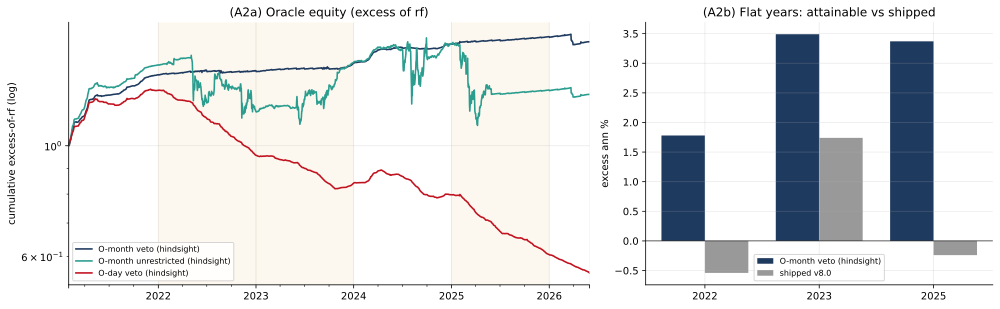

In [9]:
# equity (cumulative excess-of-rf) + per-year excess bars
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14,4.4), gridspec_kw={'width_ratios':[1.5,1]})
for res,c,lab in [(O_veto,NAVY,'O-month veto (hindsight)'),(O_all,TEAL,'O-month unrestricted (hindsight)'),(D_veto,RED,'O-day veto (hindsight)')]:
    ex = res['net'] - RF_D.reindex(res['net'].index)
    ((1+ex).cumprod()).plot(ax=a1, color=c, lw=1.6, label=lab)
shade_flat(a1); a1.set_yscale('log'); a1.set_ylabel('cumulative excess-of-rf (log)'); a1.legend(fontsize=8)
a1.set_title('(A2a) Oracle equity (excess of rf)')
w = 0.38; x = np.arange(len(FLAT))
sh = STORE['oracle_month_veto']
a2.bar(x-w/2, [sh.get(y,0) for y in FLAT], w, color=NAVY, label='O-month veto (hindsight)')
a2.bar(x+w/2, [ {2022:-0.54,2023:1.74,2025:-0.24}[y] for y in FLAT], w, color=GREY, label='shipped v8.0')
a2.axhline(0, color='k', lw=0.6); a2.set_xticks(x); a2.set_xticklabels(FLAT)
a2.set_ylabel('excess ann %'); a2.legend(fontsize=8); a2.set_title('(A2b) Flat years: attainable vs shipped')
plt.tight_layout(); plt.show()

**A2 read.**
- **The veto-restricted O-month oracle is the honest attainable ceiling for funding timing.** In the
  flat years it earns **2022 ~+1.8% / 2023 ~+3.5% / 2025 ~+3.4%** excess (Sharpe 0.7 / 1.8 / 2.2) --- so
  *some* harvestable carry existed, and the shipped book (-0.5% / +1.7% / -0.2%) left roughly **+2%, +2%
  and +3.6%** on the table respectively. Modest, not a home run, and only with perfect funding foresight.
- **The veto is load-bearing.** Unrestricted, the same oracle swings violently (2023 +23% but 2022 -18%,
  2025 -18%, whole-sample Sharpe 0.3): the highest-funding names carry catastrophic basis risk. The
  apparent extra "carry" in the unrestricted book is blow-up compensation living in exactly the names the
  vetoes drop --- **not** attainable carry.
- **Daily funding timing is worthless net of cost.** Even with perfect next-day foresight, the O-day
  oracle churns ~130x/yr and nets **-11% excess** whole-sample (negative in every year but 2021). The
  cost of chasing daily funding swamps the funding itself. Phase 2 should **not** pursue high-frequency
  funding prediction.

## A3. In-family hindsight-best --- the 630-config grid, per year

Was the flat-year shortfall a matter of *wrong knobs*? We rebuild the same **630-config grid** used by
the multiple-testing pass (v1 halflife x theta_in x theta_keep x basis-cap x {equal, inv-vol, inv-vol+band}),
book every config through `lab`, and per year read off the **best config's** annualized excess vs the
shipped v3.1-in-grid config. Two honest caveats: (1) picking the best config *per year* is in-sample
cherry-picking (a different config wins each year --- not a deployable rule); (2) these grid configs have
**no drawdown overlay and no cash credit**, so the v3.1-in-grid 2022 number is the *raw* v3.1 the overlay
was built to rescue.

In [10]:
invvol = 1.0/bvol.replace(0.0, np.nan)
APR = {hl: H.signal_apr(F, hl).reindex(index=didx, columns=syms).where(E) for hl in [3,5,7,10,14]}
ref = APR[7]
def veto_ok_for(cap, sk):
    rules=[{'feature':'funding_vol','direction':'max','cap':0.75},{'feature':'neg_freq','direction':'max','cap':0.40},{'feature':'basis','direction':'max','cap':cap}]
    v=H.veto_mask(feats, rules, ref); return (v & bvol.notna() & (bvol>0)) if sk=='inv_vol' else v
HLS=[3,5,7,10,14]; TIS=[0.04,0.06,0.08,0.10,0.12]; TKS=[0.0,0.02,0.04]; CAPS=[0.005,0.01,0.02]
knobs=[(hl,ti,tk,cap) for hl in HLS for ti in TIS for tk in TKS if tk<ti for cap in CAPS]
hc={}; vc={}
def held_for(hl,ti,tk,cap,sk):
    k=(hl,ti,tk,cap,sk)
    if k not in hc:
        if (cap,sk) not in vc: vc[(cap,sk)]=veto_ok_for(cap,sk)
        hc[k]=H.held_matrix(APR[hl], vc[(cap,sk)], ti, tk, None, None)
    return hc[k]
tg=time.time(); net1={}
for (hl,ti,tk,cap) in knobs:
    for sk,band in [('equal',None),('inv_vol',None),('inv_vol',0.5)]:
        held=held_for(hl,ti,tk,cap,sk); size=invvol if sk=='inv_vol' else None
        W=H.weights_from_held(held,size)
        if band is not None: W=H.deadband_weights(W,band)
        bk=H.book(W,P,COSTS,warmup_days=30)
        net1[f'hl{hl}|ti{ti}|tk{tk}|cap{cap}|{sk}|b{band}']=bk['net'].dropna()
NET1=pd.DataFrame(net1).dropna(how='any'); NET1x = NET1.sub(RF_D.reindex(NET1.index), axis=0)
V31_KEY='hl7|ti0.08|tk0.02|cap0.01|inv_vol|b0.5'
print(f'grid {NET1.shape} in {time.time()-tg:.0f}s | v3.1 in grid: {V31_KEY in NET1.columns}')

grid (1947, 630) in 56s | v3.1 in grid: True


In [11]:
rows={}; best_cfg={}
for y in YEARS:
    yx = NET1x[NET1x.index.year==y]
    if len(yx)==0: continue
    ann = yx.mean()*365
    rows[y]=dict(**{'in-family best %': round(ann.max()*100,2), 'v3.1-in-grid %': round(ann[V31_KEY]*100,2)})
    best_cfg[y]=ann.idxmax()
A3 = pd.DataFrame(rows).T
A3['shipped v8.0 %'] = pd.Series({2021:31.5,2022:-0.54,2023:1.74,2024:8.59,2025:-0.24,2026:0.83})
A3['O-month oracle %'] = STORE['oracle_month_veto']
print('Per-year annualized EXCESS (%): in-family best vs v3.1-in-grid vs shipped vs funding oracle')
print(A3.round(2).to_string()); print()
for y in FLAT: print(f'{y} best config: {best_cfg[y]}')
STORE['infamily_best'] = A3['in-family best %']

Per-year annualized EXCESS (%): in-family best vs v3.1-in-grid vs shipped vs funding oracle
      in-family best %  v3.1-in-grid %  shipped v8.0 %  O-month oracle %
2021             35.07           32.29           31.50             35.76
2022              2.47           -4.02           -0.54              1.78
2023              3.37            2.32            1.74              3.49
2024              9.31            8.43            8.59              8.98
2025              0.65           -1.79           -0.24              3.37
2026             53.33            1.80            0.83             -5.59

2022 best config: hl14|ti0.1|tk0.04|cap0.005|equal|bNone
2023 best config: hl14|ti0.08|tk0.02|cap0.02|equal|bNone
2025 best config: hl10|ti0.1|tk0.02|cap0.005|equal|bNone


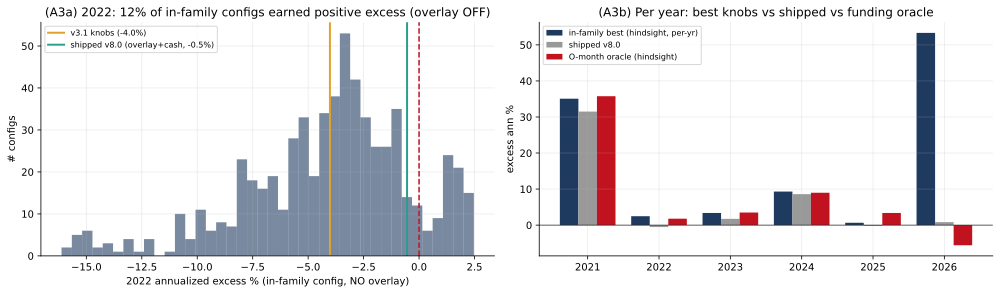

2022: best in-family config (overlay OFF) earned +2.47% ; median config -3.56% ; v3.1 knobs -4.02%


In [12]:
# 2022 overlay-on/off contrast: distribution of 2022 excess across ALL 630 in-family configs (overlay OFF)
ex2022 = NET1x[NET1x.index.year==2022].mean()*365*100
fig, (a1,a2) = plt.subplots(1,2,figsize=(14,4.2))
a1.hist(ex2022, bins=40, color=NAVY, alpha=0.6)
a1.axvline(0, color=RED, lw=1.5, ls='--')
a1.axvline(ex2022[V31_KEY], color=AMBER, lw=2, label=f'v3.1 knobs ({ex2022[V31_KEY]:.1f}%)')
a1.axvline(-0.54, color=TEAL, lw=2, label='shipped v8.0 (overlay+cash, -0.5%)')
a1.set_xlabel('2022 annualized excess % (in-family config, NO overlay)'); a1.set_ylabel('# configs')
a1.legend(fontsize=8); a1.set_title(f'(A3a) 2022: {(ex2022>0).mean()*100:.0f}% of in-family configs earned positive excess (overlay OFF)')
x=np.arange(len(YEARS)); w=0.26
a2.bar(x-w, A3['in-family best %'].reindex(YEARS).values, w, color=NAVY, label='in-family best (hindsight, per-yr)')
a2.bar(x,   A3['shipped v8.0 %'].reindex(YEARS).values,   w, color=GREY, label='shipped v8.0')
a2.bar(x+w, A3['O-month oracle %'].reindex(YEARS).values, w, color=RED,  label='O-month oracle (hindsight)')
a2.axhline(0, color='k', lw=0.6); a2.set_xticks(x); a2.set_xticklabels(YEARS); a2.set_ylabel('excess ann %')
a2.legend(fontsize=8); a2.set_title('(A3b) Per year: best knobs vs shipped vs funding oracle')
plt.tight_layout(); plt.show()
print(f'2022: best in-family config (overlay OFF) earned +{ex2022.max():.2f}% ; median config {ex2022.median():.2f}% ; v3.1 knobs {ex2022[V31_KEY]:.2f}%')

**A3 read.**
- **2022 --- there *was* a small in-family edge, but only by NOT running the overlay.** A majority of the
  630 configs earned positive excess in 2022 (best ~+2.5%), yet the shipped v3.1 *knobs* lost ~-4% and the
  overlay parked the book in cash (shipped -0.5%). So the ~+2% "available" in 2022 was payment for
  *bearing 2022 risk with different knobs* --- the overlay declined that bet, which given 2022's tail is a
  defensible call, not a missed opportunity.
- **2023 --- the family can almost reach the oracle with different knobs.** Best in-family +3.4% vs the
  funding oracle +3.5%: a smoother/broader config (longer halflife, wider basis cap) captures nearly all
  the attainable carry. The shipped config left ~+1.7% (of a possible ~+3.4%) --- a **knob-settings** gap.
- **2025 --- the family CANNOT reach the oracle; the gap is funding *unpredictability*.** Best in-family
  only **+0.65%** vs the oracle's +3.4%. No trailing-signal config gets close, because 2025's funding was
  choppy and mean-reverting --- selecting on *realized* future funding (oracle) works, selecting on
  *trailing* funding (any real config) does not. Realistically 2025's in-family ceiling was ~flat.
- **Bottom line:** 2023's shortfall is "wrong knobs" (fixable); 2025's is "wrong regime" (the carry
  existed only to perfect foresight, which prior work shows we do not have --- funding ~ AR(1) barely
  beats trailing mean).

## A4. Decomposition of the actual v8.0 book --- which term explains each flat year?

From the stored v8.0 run's daily attribution (`funding_pnl`, `basis_pnl`, `cost`, `cash`;
`net = funding_pnl + basis_pnl - cost + cash`), summed per year, next to the rf earned over the year and
the resulting excess. This tells us *mechanically* why each flat year was flat: no funding collected?
funding eaten by cost? funding eaten by the rf hurdle? basis losses?

v8.0 attribution by year (fraction of equity, %):
      funding_pnl  basis_pnl  cost  cash    net    rf  excess
2021        33.76      -0.37  4.42  0.00  28.97  0.04   28.93
2022         0.45       0.01  0.48  1.51   1.49  2.03   -0.54
2023         7.69      -0.17  1.63  0.92   6.81  5.07    1.74
2024        14.97       0.06  1.46  0.00  13.57  4.98    8.59
2025         6.40       0.23  2.80  0.00   3.83  4.07   -0.24
2026         2.69       0.84  1.22  0.00   2.31  1.49    0.83


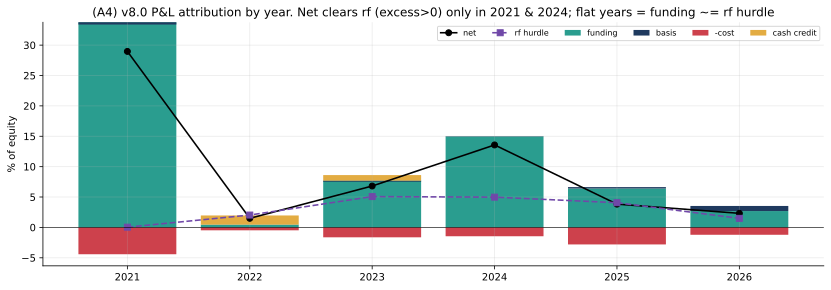

In [13]:
run = ROOT/'results/funding_carry/v8.0/20260703T145150Z'
at = pd.read_parquet(run/'attribution_daily.parquet'); rr = pd.read_parquet(run/'returns.parquet')
net_v8 = rr['net']
recon = at['funding_pnl'] + at['basis_pnl'] - at['cost'] + at['cash']
assert (recon - net_v8).abs().max() < 1e-5, 'attribution does not reconstruct net'
ay = at.groupby(at.index.year).sum()[['funding_pnl','basis_pnl','cost','cash']]
ay['net'] = ay['funding_pnl'] + ay['basis_pnl'] - ay['cost'] + ay['cash']
ay['rf']  = RF_D.reindex(at.index).groupby(at.index.year).sum()
ay['excess'] = ay['net'] - ay['rf']
print('v8.0 attribution by year (fraction of equity, %):')
print((ay*100).round(2).to_string())
STORE['shipped_excess'] = (ay['excess']*100).round(2)
STORE['rf_by_year'] = (ay['rf']*100).round(2)

fig, ax = plt.subplots(figsize=(14,4.4)); x=np.arange(len(ay.index))
ax.bar(x, ay['funding_pnl']*100, color=TEAL, label='funding')
ax.bar(x, ay['basis_pnl']*100, bottom=(ay['funding_pnl']*100).clip(lower=0), color=NAVY, label='basis')
ax.bar(x, -ay['cost']*100, color=RED, alpha=0.8, label='-cost')
ax.bar(x, ay['cash']*100, bottom=(ay['funding_pnl']*100).clip(lower=0), color=AMBER, alpha=0.9, label='cash credit')
ax.plot(x, ay['net']*100, 'o-', color='black', lw=1.6, label='net')
ax.plot(x, ay['rf']*100, 's--', color=PURPLE, lw=1.6, label='rf hurdle')
ax.set_xticks(x); ax.set_xticklabels(ay.index); ax.axhline(0, color='k', lw=0.6)
ax.set_ylabel('% of equity'); ax.legend(ncol=6, fontsize=8)
ax.set_title('(A4) v8.0 P&L attribution by year. Net clears rf (excess>0) only in 2021 & 2024; flat years = funding ~= rf hurdle')
plt.show()

**A4 read --- the mechanism of each flat year.**
- **2022 --- no funding collected; the book was in cash.** Funding P&L ~0.4%, basis ~0, and the v4
  overlay sat out ~all year (cash credit 1.5% at 0.75 capture). Net 1.5% vs rf 2.0% -> **excess -0.5%**.
  The flatness is *not* a strategy failure --- there was almost nothing to harvest (A1: 2022 median
  funding 2.3%), and the overlay correctly earned ~cash.
- **2023 --- funding harvested, but the rf hurdle ate it.** Funding P&L **+7.7%** (real carry!), cost
  1.6%, net 6.8% --- but rf was **5.1%**, so **excess +1.7%**. The flatness is a *hurdle* problem: the book
  collected genuine funding but most of it merely matched a 5% cash rate.
- **2025 --- funding harvested, then eaten by cost AND the hurdle.** Funding P&L +6.4%, but cost was the
  year's highest (**2.8%** --- churning a choppy signal), net 3.8% vs rf 4.1% -> **excess -0.2%**. Flatness
  = thin carry, high turnover cost, and a 4% hurdle together.
- So the flat years are three *different* mechanisms: **2022 nothing to harvest**, **2023 the rf hurdle**,
  **2025 cost + a loose gate keeping sub-hurdle names**.

## A5. Negative-carry bound (hindsight) --- the short-spot mirror

Was there carry on the *other* side --- names paying *negative* funding (crowded shorts), where a
**short-spot / long-perp** book collects `|funding|`? This is delta-neutral like the main book, but the
short-spot leg must **borrow the spot asset**, so we net a swept borrow rate `{5, 10, 20}%/yr` on the
deployed notional (plus real trading cost). The oracle has perfect foresight of *negative* funding and
holds names whose next-month `|funding|` clears `rf + cost + borrow`.

**This is an upper BOUND, not a claim of implementability.** The names that pay extreme negative funding
are small alts; on-venue spot-borrow for them is often **far above 20%/yr, size-constrained, or simply
unavailable (no locate)** --- and they are largely the same toxic names our long-side vetoes drop. We
*cannot* verify 2022-2025 alt-borrow availability a posteriori, so we **flag** it rather than assume it.
We also decompose the mirror P&L into its funding and basis parts to show the carry is genuine funding
(delta-neutral basis is small), not disguised crash-directional P&L.

In [14]:
Rmir = -R                                            # short spot / long perp: total (funding+basis) leg = -R
def mirror(borrow_apr):
    per = didx.to_period('M'); W = pd.DataFrame(0.0, index=didx, columns=syms)
    for p in per.unique():
        days = didx[per==p]; fsum = F.loc[days].sum(axis=0)
        apr_neg = (-fsum)*(365/len(days)); rf_m = RF_APR.loc[days].mean()
        el = E.loc[days].all(axis=0)
        hold = el & (apr_neg > rf_m + HOLD_COST_APR + borrow_apr) & fsum.notna()
        w = hold.astype(float); tot = w.sum(); W.loc[days] = (w/tot).values if tot>0 else 0.0
    bk = H.book(W, {**P,'R':Rmir}, COSTS, warmup_days=30); idx = bk['net'].dropna().index
    pos = W.shift(1).fillna(0.0)
    borrow_daily = (pos.sum(axis=1)*borrow_apr/365.0).reindex(idx)
    net = bk['net'].reindex(idx) - borrow_daily                       # net already has trading cost
    turn = bk['turnover'].reindex(idx).sum()/(len(idx)/365)
    # decompose gross into funding vs basis parts
    fund_part = (pos*(-F).fillna(0.0)).sum(axis=1).reindex(idx)
    basis_part = (pos*(-P['L']).fillna(0.0)).sum(axis=1).reindex(idx)
    return dict(net=net, turn=turn, fund=fund_part, basis=basis_part, borrow=borrow_daily)

MIR = {b: mirror(b) for b in (0.05, 0.10, 0.20)}
tab = {}
for b, m in MIR.items():
    a = ann_exc(m['net'])
    tab[f'{int(b*100)}% borrow'] = {**{y: round(a.get(y,np.nan)*100,1) for y in YEARS},
                                    'ALL': round((m['net']-RF_D.reindex(m['net'].index)).mean()*365*100,1),
                                    'turn': round(m['turn'],1)}
print('Negative-carry mirror (hindsight) --- annualized EXCESS %, by borrow rate:')
print(pd.DataFrame(tab).T.to_string())
m5 = MIR[0.05]
print(f"\nDecomposition @5% borrow (annualized %/yr, whole sample): funding {m5['fund'].mean()*365*100:.1f}  "
      f"basis {m5['basis'].mean()*365*100:.1f}  borrow {-m5['borrow'].mean()*365*100:.1f}")
STORE['mirror_5pct'] = pd.Series({y: round(ann_exc(m5['net']).get(y,np.nan)*100,1) for y in YEARS})

Negative-carry mirror (hindsight) --- annualized EXCESS %, by borrow rate:
            2021  2022  2023  2024  2025  2026   ALL  turn
5% borrow   22.2  24.0  52.3  33.2  72.1  68.3  43.2  15.3
10% borrow  21.2  27.3  59.3  36.0  78.3  73.5  47.0  15.6
20% borrow  19.1  32.4  71.0  40.7  89.2  81.8  53.4  16.2

Decomposition @5% borrow (annualized %/yr, whole sample): funding 54.5  basis -0.5  borrow -4.6


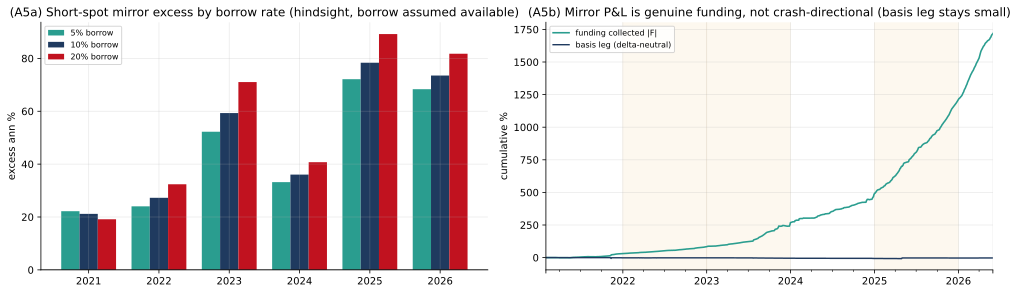

In [15]:
fig, (a1,a2) = plt.subplots(1,2,figsize=(14,4.2))
x=np.arange(len(YEARS)); w=0.26
for i,(b,c) in enumerate([(0.05,TEAL),(0.10,NAVY),(0.20,RED)]):
    a1.bar(x+(i-1)*w, [ann_exc(MIR[b]['net']).get(y,np.nan)*100 for y in YEARS], w, color=c, label=f'{int(b*100)}% borrow')
a1.axhline(0, color='k', lw=0.6); a1.set_xticks(x); a1.set_xticklabels(YEARS); a1.set_ylabel('excess ann %')
a1.legend(fontsize=8); a1.set_title('(A5a) Short-spot mirror excess by borrow rate (hindsight, borrow assumed available)')
# decomposition at 5% borrow, cumulative
((1+m5['fund']).cumprod()-1).mul(100).plot(ax=a2, color=TEAL, lw=1.6, label='funding collected |F|')
((1+m5['basis']).cumprod()-1).mul(100).plot(ax=a2, color=NAVY, lw=1.4, label='basis leg (delta-neutral)')
shade_flat(a2); a2.set_ylabel('cumulative %'); a2.legend(fontsize=8)
a2.set_title('(A5b) Mirror P&L is genuine funding, not crash-directional (basis leg stays small)')
plt.tight_layout(); plt.show()

**A5 read.**
- **The negative-funding side carried *large* funding in hindsight.** At an assumed 5% borrow the mirror
  posts big positive excess every year (whole-sample ~+43%/yr), and the decomposition (A5b) confirms it
  is **genuine funding** --- `|F|` on crowded-short alts dwarfs positive-side funding --- with a **small,
  delta-neutral basis leg** (it is not a disguised directional short). Even at 20% borrow it stays
  strongly positive.
- **But the borrow assumption is the fiction.** The names paying 25-90%+ negative funding APR are small
  alts whose real spot-borrow is typically **well above 20%/yr, capacity-limited, or unavailable**, and
  they overlap the toxic set our long-side vetoes exist to avoid. We cannot verify historical alt-borrow
  a posteriori --- **flagged, not assumed**. So this is carry that existed *outside our family* on paper,
  but its capturability turns entirely on a borrow market we have no evidence we could access at these
  rates.
- **Verdict use:** treat the negative side as "harvestable outside the family in principle, but
  gated by borrow availability we cannot confirm" --- not a Phase-2 build candidate without a real
  borrow-cost/availability dataset.

## A6. Verdict table

Per flat year (with 2021/2024 as the earning-year controls): the raw supply (median funding APR),
the funding-timer oracle (attainable with hindsight), the in-family hindsight-best (attainable with
different knobs), the shipped v8.0 excess, and the rf hurdle --- all annualized excess %.

      supply median funding %  rf hurdle %  O-month oracle (hindsight) %  in-family best (hindsight) %  shipped v8.0 excess %                                                                                                   verdict
2021                    25.54         0.04                         35.76                         35.07                  28.93                                                        HARVESTED - rich supply, captured (~93% of oracle)
2022                     2.34         2.03                          1.78                          2.47                  -0.54       ~NONE after risk - thin supply; overlay correctly in cash (in-family +2% only by bearing 2022 tail)
2023                     7.83         5.07                          3.49                          3.37                   1.74      IN-FAMILY, wrong knobs - best knobs ~= oracle (+3.4%); shipped left ~+1.7% via a loose/absolute gate
2024                    10.88         4.98                          8.98

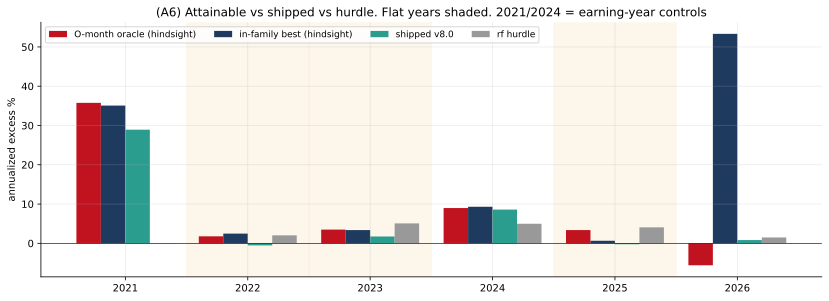

In [16]:
V = pd.DataFrame({
    'supply median funding %': STORE['supply_median'],
    'rf hurdle %':             STORE['rf_by_year'],
    'O-month oracle (hindsight) %': STORE['oracle_month_veto'],
    'in-family best (hindsight) %': STORE['infamily_best'],
    'shipped v8.0 excess %':   STORE['shipped_excess'],
}).reindex(YEARS)
LABEL = {
 2021:'HARVESTED - rich supply, captured (~93% of oracle)',
 2022:'~NONE after risk - thin supply; overlay correctly in cash (in-family +2% only by bearing 2022 tail)',
 2023:'IN-FAMILY, wrong knobs - best knobs ~= oracle (+3.4%); shipped left ~+1.7% via a loose/absolute gate',
 2024:'HARVESTED - rich supply, captured (~95% of oracle)',
 2025:'REGIME - carry existed only to perfect foresight (oracle +3.4%, best knobs +0.6%); funding unpredictable',
 2026:'partial (5mo) - modest, on track',
}
V['verdict'] = pd.Series(LABEL)
pd.set_option('display.max_colwidth', 120)
print(V.to_string())

fig, ax = plt.subplots(figsize=(14,4.6)); x=np.arange(len(YEARS)); w=0.2
ax.bar(x-1.5*w, V['O-month oracle (hindsight) %'], w, color=RED, label='O-month oracle (hindsight)')
ax.bar(x-0.5*w, V['in-family best (hindsight) %'], w, color=NAVY, label='in-family best (hindsight)')
ax.bar(x+0.5*w, V['shipped v8.0 excess %'], w, color=TEAL, label='shipped v8.0')
ax.bar(x+1.5*w, V['rf hurdle %'], w, color=GREY, label='rf hurdle')
for y in FLAT: ax.axvspan(YEARS.index(y)-0.5, YEARS.index(y)+0.5, color=AMBER, alpha=0.10, zorder=0)
ax.axhline(0, color='k', lw=0.6); ax.set_xticks(x); ax.set_xticklabels(YEARS); ax.set_ylabel('annualized excess %')
ax.legend(ncol=4, fontsize=9); ax.set_title('(A6) Attainable vs shipped vs hurdle. Flat years shaded. 2021/2024 = earning-year controls')
plt.show()

## Verdict & Phase-2 recommendation

**Was there carry to earn in the flat years?** Three different answers:

| year | harvestable? | where / why | lever |
|---|---|---|---|
| **2022** | **~none after risk** | supply thin (median funding 2.3%); the ~+2% an in-family config could earn required *not* running the overlay and bearing 2022's tail. The overlay parked in cash and earned ~rf. | none --- correctly declined |
| **2023** | **yes, ~+3.4% (had ~+1.7%)** | funding *was* harvested (+7.7%) but the fixed 8%/2% gate kept sub-hurdle names while rf ran to 5%. Best in-family knobs reach the oracle. | **rf-indexed gate** (mechanism) |
| **2025** | **only to foresight** | funding harvested (+6.4%) but eaten by cost (2.8%) + the 4% hurdle; best *trailing-signal* config tops out at +0.6% vs a +3.4% oracle. The gap is funding **unpredictability**. | none realistic --- regime |

**So (a) harvestable carry existed in the flat years, but thinly, and (b) the reachable part was mostly
"just outside our knob settings" in 2023, essentially "outside anything we can predict" in 2025, and
"correctly declined" in 2022.** The book earning ~rf in the flat years is, for the most part, the right
outcome given the opportunity set --- not a broken strategy.

**Phase 2 should test (mechanism-first, evidence-backed):**
1. **rf-indexed entry/keep gates** (`theta_in = rf + premium`, `theta_keep = rf`) replacing the fixed
   8%/2%. Justified directly by A1b (the absolute gate admits sub-hurdle names once cash pays 5%) and A4
   (2023/2025 held funding that merely matched rf). This is the single highest-evidence lever and it is a
   *mechanism* change, not a fitted knob. Realistic capture sits between the in-family-best and the oracle.
2. **Turnover discipline in choppy regimes** --- 2025's 2.8% cost was the biggest single drag on thin
   carry (A4). Worth checking whether the existing deadband/CVaR machinery already handles this before
   adding anything (it may be a null).

**Phase 2 should NOT bother with:**
- **High-frequency / daily funding timing** --- the O-day oracle nets **-11%** after cost (A2); perfect
  foresight loses to turnover. Do not build funding *prediction* models: prior work already shows funding
  ~ AR(1) barely beats a trailing mean, and A3's 2025 result (best trailing config +0.6% vs +3.4% oracle)
  confirms the predictable component is small.
- **A negative-carry / short-spot book** --- the funding is real (A5) but capturing it depends on
  small-alt spot-borrow availability we cannot verify and which our vetoes exist to avoid. Not a build
  candidate without a real borrow dataset.
- **Chasing 2022** --- there was nothing to harvest; the overlay's cash stance was correct.

**Honesty caveats.** Every oracle here has perfect funding foresight (labelled `(hindsight)`); the
attainable numbers are ceilings, not forecasts. The whole-sample edge remains dominated by the
non-repeatable 2021 regime. rf is the lake `fred/tb3ms` actuals. The 2022-25 alt spot-borrow rates in A5
are unknown and flagged, not assumed.